In [1]:
from matplotlib import pyplot as plt
from matplotlib import colors
import numpy as np
from matplotlib.patches import Path, PathPatch
import pandas as pd
from shapely.geometry import Point, shape, Polygon
from shapely.ops import unary_union, cascaded_union
from geopandas.tools import sjoin
import geopandas as gpd
from netCDF4 import Dataset
from cartopy import crs as ccrs
from cartopy.io.shapereader import Reader
from sklearn.metrics import mean_squared_error
import scipy.stats as st
from sklearn.linear_model import LinearRegression
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.feature import LAKES
import geopandas as gpd
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import cmasher as cmr
from netCDF4 import Dataset
from matplotlib.offsetbox import AnchoredText
from matplotlib.colors import TwoSlopeNorm

C:\Users\x12la\AppData\Local\Temp\ipykernel_5940\3630898004.py:8: UserWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas will still use PyGEOS by default for now. To force to use and test Shapely 2.0, you have to set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In a future release, GeoPandas will switch to using Shapely by default. If you are using PyGEOS directly (calling PyGEOS functions on geometries from GeoPandas), this will then stop working and you are encouraged to migrate from PyGEOS to Shapely 2.0 (https://shapely.readthedocs.io/en/latest/migration_pygeos.html).
  from geopandas.tools import sjoin


In [2]:
# Get lat/lon from LADCO grid and find corners of domain
# this is to be used for map extents
grid='C:/Users/x12la/Desktop/latlon_ChicagoLADCO_d03.nc'
# Silly note- DO2 file uses capital LAT LON and d03 uses lowercase 
cmaq_lon,cmaq_lat=np.array(Dataset(grid)['lon']),np.array(Dataset(grid)['lat'])
llat,ulat,llon,ulon=cmaq_lat.min(), cmaq_lat.max(), cmaq_lon.min(), cmaq_lon.max()
print(llat,ulat,llon,ulon)

#CMAP 7 counties surrounding Chicago/Cook County
cmap_cty = gpd.read_file('C:/Users/x12la/Desktop/Scripts/CMAP_cty.shp')
cmap_cty = cmap_cty.to_crs('EPSG:4326')

40.210953 44.045914 -90.07886 -84.51282


In [3]:
# LOCUS idling with the HDV spatial surrogate — new baseline for this study
gas_LOCUSIdlingHDVSpatial = gpd.read_file("emis_mole_onroad_gas_2023_LOCUSIdlingHDVSpatial_annualavg.shp").to_crs("EPSG:4326")
diesel_LOCUSIdlingHDVSpatial = gpd.read_file("emis_mole_onroad_diesel_2023_LOCUSIdlingHDVSpatial_annualavg.shp").to_crs("EPSG:4326")

# find the shared numeric columns and add the gas and diesel emissions together
common_cols = gas_LOCUSIdlingHDVSpatial.columns.intersection(diesel_LOCUSIdlingHDVSpatial.columns)
cols_to_sum = [c for c in common_cols if c not in ["geometry", "lat", "lon", "lat_m", "lon_m"] and pd.api.types.is_numeric_dtype(gas_LOCUSIdlingHDVSpatial[c])]

onroad_total_LOCUSIdlingHDVSpatial = gas_LOCUSIdlingHDVSpatial.copy()
onroad_total_LOCUSIdlingHDVSpatial[cols_to_sum] = gas_LOCUSIdlingHDVSpatial[cols_to_sum].fillna(0).to_numpy() + diesel_LOCUSIdlingHDVSpatial[cols_to_sum].fillna(0).to_numpy()
onroad_total_LOCUSIdlingHDVSpatial_cmap = gpd.clip(onroad_total_LOCUSIdlingHDVSpatial, cmap_cty)


# accelerated fleet renewal scenario
gas_Renewal = gpd.read_file("emis_mole_onroad_gas_2023_Renewal_annualavg.shp").to_crs("EPSG:4326")
diesel_Renewal = gpd.read_file("emis_mole_onroad_diesel_2023_Renewal_annualavg.shp").to_crs("EPSG:4326")

# add the gas and diesel emissions together
common_cols = gas_Renewal.columns.intersection(diesel_Renewal.columns)
cols_to_sum = [c for c in common_cols if c not in ["geometry", "lat", "lon", "lat_m", "lon_m"] and pd.api.types.is_numeric_dtype(gas_Renewal[c])]

onroad_total_Renewal = gas_Renewal.copy()
onroad_total_Renewal[cols_to_sum] = gas_Renewal[cols_to_sum].fillna(0).to_numpy() + diesel_Renewal[cols_to_sum].fillna(0).to_numpy()
onroad_total_Renewal_cmap = gpd.clip(onroad_total_Renewal, cmap_cty)


# zero-legacy scenario with all pre-2010 trucks and their activity removed
gas_ZeroPre2010s = gpd.read_file("emis_mole_onroad_gas_2023_ZeroPre2010s_annualavg.shp").to_crs("EPSG:4326")
diesel_ZeroPre2010s = gpd.read_file("emis_mole_onroad_diesel_2023_ZeroPre2010s_annualavg.shp").to_crs("EPSG:4326")

# add the gas and diesel emissions together
common_cols = gas_ZeroPre2010s.columns.intersection(diesel_ZeroPre2010s.columns)
cols_to_sum = [c for c in common_cols if c not in ["geometry", "lat", "lon", "lat_m", "lon_m"] and pd.api.types.is_numeric_dtype(gas_ZeroPre2010s[c])]

onroad_total_ZeroPre2010s = gas_ZeroPre2010s.copy()
onroad_total_ZeroPre2010s[cols_to_sum] = gas_ZeroPre2010s[cols_to_sum].fillna(0).to_numpy() + diesel_ZeroPre2010s[cols_to_sum].fillna(0).to_numpy()
onroad_total_ZeroPre2010s_cmap = gpd.clip(onroad_total_ZeroPre2010s, cmap_cty)

# quick check that everything loaded and clipped as expected
print("LOCUS idling (HDVSpatial):", onroad_total_LOCUSIdlingHDVSpatial.shape, onroad_total_LOCUSIdlingHDVSpatial_cmap.shape)
print("Renewal:", onroad_total_Renewal.shape, onroad_total_Renewal_cmap.shape)
print("ZeroPre2010s:", onroad_total_ZeroPre2010s.shape, onroad_total_ZeroPre2010s_cmap.shape)

LOCUS idling (HDVSpatial): (90720, 67) (6070, 67)
Renewal: (90720, 67) (6070, 67)
ZeroPre2010s: (90720, 67) (6070, 67)


In [4]:
def calc_nox_peryear(gdf, cell_km=1.33):
    """
    Add 'NOX_peryear' in tons/km^2/year.
    'NO' and 'NO2' are in mol/s 
    From Google:
    NO molecular weight 30.0061 g/mol
    NO2 molecular weight 46.005 g/mol

    Maths:
    mol/s * (g/mol) -> g/s
    (g/s * 3600)/1e6 -> metric tons/hour
    Divide by cell area (km^2) to get tons/km^2/hour
    tons/km^2/hour * 8760 = tons/km^2/year
    """
    
    if "NOX_peryear" in gdf.columns:
        return gdf

    for col in ["NO", "NO2"]:
        if col not in gdf.columns:
            raise KeyError(f"Missing '{col}' to derive NOX_peryear.")
    area_km2 = (1.33)**2
    nox_ton_per_hr = ((gdf["NO"]  * 30.0061 * 3600.0 / 1e6) / area_km2 + (gdf["NO2"] * 46.005  * 3600.0 / 1e6) / area_km2)
    gdf["NOX_peryear"] = nox_ton_per_hr * 8760.0
    return gdf


def calc_pm25_peryear(gdf, species=None, cell_km=1.33):
    """
    Add 'PM25_peryear' in tons/km^2/year.
    PM species are provided in g/s
 
    g/s
    (g/s * 3600)/1e6 -> tons/hour
    Divide by cell area (km^2) to get tons/km^2/hour
    tons/km^2/hour * 8760 = tons/km^2/year
    """
    if "PM25_peryear" in gdf.columns:
        return gdf

    if species is None:
        species = ['PEC','POC','PNCOM','PSO4','PNO3','PFE','PAL','PSI','PTI',
                   'PCA','PMG','PK','PMN','PNA','PCL','PMOTHR']
    missing = [s for s in species if s not in gdf.columns]
    
    area_km2 = (1.33)**2
    # Sum species (g/s) -> tons/hour -> /km^2 -> annualize
    pm25_ton_per_hr = gdf[species].sum(axis=1) * 3600.0 / 1e6
    gdf["PM25_peryear"] = (pm25_ton_per_hr * 8760.0) / area_km2
    return gdf

In [5]:
# calculate annual NOx and PM2.5 emissions for each scenario
onroad_total_LOCUSIdlingHDVSpatial_cmap = calc_nox_peryear(onroad_total_LOCUSIdlingHDVSpatial_cmap)
onroad_total_Renewal_cmap = calc_nox_peryear(onroad_total_Renewal_cmap)
onroad_total_ZeroPre2010s_cmap = calc_nox_peryear(onroad_total_ZeroPre2010s_cmap)

onroad_total_LOCUSIdlingHDVSpatial_cmap = calc_pm25_peryear(onroad_total_LOCUSIdlingHDVSpatial_cmap)
onroad_total_Renewal_cmap = calc_pm25_peryear(onroad_total_Renewal_cmap)
onroad_total_ZeroPre2010s_cmap = calc_pm25_peryear(onroad_total_ZeroPre2010s_cmap)


# calculate the difference between each scenario and the LOCUS idling baseline
onroad_total_LOCUSIdlingHDVSpatial_cmap["diff_nox"] = onroad_total_LOCUSIdlingHDVSpatial_cmap["NOX_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["NOX_peryear"].to_numpy()
onroad_total_Renewal_cmap["diff_nox"] = onroad_total_Renewal_cmap["NOX_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["NOX_peryear"].to_numpy()
onroad_total_ZeroPre2010s_cmap["diff_nox"] = onroad_total_ZeroPre2010s_cmap["NOX_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["NOX_peryear"].to_numpy()

onroad_total_LOCUSIdlingHDVSpatial_cmap["diff_pm25"] = onroad_total_LOCUSIdlingHDVSpatial_cmap["PM25_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["PM25_peryear"].to_numpy()
onroad_total_Renewal_cmap["diff_pm25"] = onroad_total_Renewal_cmap["PM25_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["PM25_peryear"].to_numpy()
onroad_total_ZeroPre2010s_cmap["diff_pm25"] = onroad_total_ZeroPre2010s_cmap["PM25_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["PM25_peryear"].to_numpy()


# policy differences relative to the LOCUS idling baseline
onroad_total_Renewal_cmap["diff_nox_from_LOCUSIdlingHDVSpatial"] = onroad_total_Renewal_cmap["NOX_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["NOX_peryear"].to_numpy()
onroad_total_ZeroPre2010s_cmap["diff_nox_from_LOCUSIdlingHDVSpatial"] = onroad_total_ZeroPre2010s_cmap["NOX_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["NOX_peryear"].to_numpy()

onroad_total_Renewal_cmap["diff_pm25_from_LOCUSIdlingHDVSpatial"] = onroad_total_Renewal_cmap["PM25_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["PM25_peryear"].to_numpy()
onroad_total_ZeroPre2010s_cmap["diff_pm25_from_LOCUSIdlingHDVSpatial"] = onroad_total_ZeroPre2010s_cmap["PM25_peryear"].to_numpy() - onroad_total_LOCUSIdlingHDVSpatial_cmap["PM25_peryear"].to_numpy()

In [6]:
minx, miny, maxx, maxy = cmap_cty.total_bounds
extent_xy = (minx, maxx, miny, maxy)

In [7]:
# compare total CO2 emissions and calculate how much legacy-truck CO2 is removed through renewal
scenario_gdfs = {
    "LOCUSIdlingHDVSpatial": onroad_total_LOCUSIdlingHDVSpatial_cmap,
    "Renewal": onroad_total_Renewal_cmap,
    "ZeroPre2010s": onroad_total_ZeroPre2010s_cmap}

col = "CO2_INV"
seconds_per_year = 3600 * 8760
grams_per_metric_ton = 1e6

# sum CO2 across the domain and convert from g/s to metric tons/year
totals = {}
for name, gdf in scenario_gdfs.items():
    if col not in gdf.columns:
        raise KeyError(f"{col} not found in {name}")
    totals[name] = gdf[col].fillna(0).sum() * seconds_per_year / grams_per_metric_ton

# print the total CO2 emissions for each scenario
print("\nTotal CO2 emissions by scenario")
for name, total in totals.items():
    print(f"{name:25s}: {total:,.2f} metric tons/year")

# pull out the scenario totals so the comparisons are easier to follow
baseline = totals["LOCUSIdlingHDVSpatial"]
renewal = totals["Renewal"]
zero_legacy = totals["ZeroPre2010s"]


# calculate the legacy-truck contribution and the reduction achieved through renewal
legacy_co2 = baseline - zero_legacy
renewal_reduction = baseline - renewal
remaining_after_renewal = renewal - zero_legacy

pct_legacy_removed_by_renewal = renewal_reduction / legacy_co2 * 100 if legacy_co2 != 0 else np.nan
pct_legacy_remaining = remaining_after_renewal / legacy_co2 * 100 if legacy_co2 != 0 else np.nan

# summarize how accelerated renewal changes the legacy-truck CO2 contribution
print("\nLegacy-truck CO2 and accelerated renewal")
print(f"CO2 attributable to legacy trucks: {legacy_co2:,.2f} metric tons/year")
print(f"CO2 reduction achieved by accelerated renewal: {renewal_reduction:,.2f} metric tons/year")
print(f"Accelerated renewal eliminates {pct_legacy_removed_by_renewal:.2f}% of the CO2 attributable to legacy trucks.")
print(f"The replacement fleet retains {remaining_after_renewal:,.2f} metric tons/year, or {pct_legacy_remaining:.2f}% of the legacy-truck CO2 contribution.")


Total CO2 emissions by scenario
LOCUSIdlingHDVSpatial    : 30,870,405.75 metric tons/year
Renewal                  : 30,361,469.66 metric tons/year
ZeroPre2010s             : 29,413,583.08 metric tons/year

Legacy-truck CO2 and accelerated renewal
CO2 attributable to legacy trucks: 1,456,822.67 metric tons/year
CO2 reduction achieved by accelerated renewal: 508,936.09 metric tons/year
Accelerated renewal eliminates 34.93% of the CO2 attributable to legacy trucks.
The replacement fleet retains 947,886.58 metric tons/year, or 65.07% of the legacy-truck CO2 contribution.


In [8]:
# compare total NOx and PM2.5 emissions across the three scenarios
scenario_gdfs = {
    "LOCUSIdlingHDVSpatial": onroad_total_LOCUSIdlingHDVSpatial_cmap,
    "Renewal": onroad_total_Renewal_cmap,
    "ZeroPre2010s": onroad_total_ZeroPre2010s_cmap}

cell_area_km2 = 1.33**2
pollutants = {
    "NOx": "NOX_peryear",
    "PM2.5": "PM25_peryear"}

for pollutant, col in pollutants.items():
    # multiply the emission density by grid-cell area and sum across the domain
    totals = {}

    for name, gdf in scenario_gdfs.items():
        if col not in gdf.columns:
            raise KeyError(f"{col} not found in {name}")

        totals[name] = (gdf[col].fillna(0) * cell_area_km2).sum()


    # print total annual emissions for each scenario
    print(f"\nTotal {pollutant} emissions by scenario")

    for name, total in totals.items():
        print(f"{name:25s}: {total:,.2f} tons/year")


    # calculate the change from the LOCUS idling baseline
    policy_base = totals["LOCUSIdlingHDVSpatial"]

    print(f"\n{pollutant} changes relative to the LOCUS idling baseline")

    for name in ["Renewal", "ZeroPre2010s"]:
        diff = totals[name] - policy_base
        pct_diff = diff / policy_base * 100 if policy_base != 0 else np.nan
        print(f"{name:25s} - LOCUSIdlingHDVSpatial: Δ = {diff:,.2f} tons/year ({pct_diff:+.2f}%)")


    # compare every scenario pair
    scenario_names = list(totals)

    print(f"\Differences for {pollutant}")

    for i in range(len(scenario_names)):
        for j in range(i + 1, len(scenario_names)):
            name1 = scenario_names[i]
            name2 = scenario_names[j]
            diff = totals[name2] - totals[name1]
            pct_diff = diff / totals[name1] * 100 if totals[name1] != 0 else np.nan
            print(f"{name2:25s} - {name1:25s}: Δ = {diff:,.2f} tons/year ({pct_diff:+.2f}%)")


Total NOx emissions by scenario
LOCUSIdlingHDVSpatial    : 23,621.53 tons/year
Renewal                  : 16,734.49 tons/year
ZeroPre2010s             : 15,780.39 tons/year

NOx changes relative to the LOCUS idling baseline
Renewal                   - LOCUSIdlingHDVSpatial: Δ = -6,887.04 tons/year (-29.16%)
ZeroPre2010s              - LOCUSIdlingHDVSpatial: Δ = -7,841.14 tons/year (-33.19%)
\Differences for NOx
Renewal                   - LOCUSIdlingHDVSpatial    : Δ = -6,887.04 tons/year (-29.16%)
ZeroPre2010s              - LOCUSIdlingHDVSpatial    : Δ = -7,841.14 tons/year (-33.19%)
ZeroPre2010s              - Renewal                  : Δ = -954.10 tons/year (-5.70%)

Total PM2.5 emissions by scenario
LOCUSIdlingHDVSpatial    : 1,235.79 tons/year
Renewal                  : 834.44 tons/year
ZeroPre2010s             : 812.52 tons/year

PM2.5 changes relative to the LOCUS idling baseline
Renewal                   - LOCUSIdlingHDVSpatial: Δ = -401.35 tons/year (-32.48%)
ZeroPre2010s   

In [9]:
# set the ranges used for the absolute and scenario-difference maps
PM25_N_BINS = 16
PM25_VMIN = 0.0
PM25_VMAX = 2.0
PM25_DIFF_MIN = -0.5
PM25_DIFF_MAX = 0.5

NOX_N_BINS = 20
NOX_VMIN = 0.0
NOX_VMAX = 40.0
NOX_DIFF_MIN = -20.0
NOX_DIFF_MAX = 20.0


# use discrete color bins for the absolute PM2.5 maps
pm_colors = cmr.gothic_r(np.linspace(0, 1, PM25_N_BINS))
cmap_abs_pm = ListedColormap(pm_colors)
norm_abs_pm = BoundaryNorm(np.linspace(PM25_VMIN, PM25_VMAX, PM25_N_BINS + 1), cmap_abs_pm.N)

# use an odd number of colors so white stays centered at zero
N_DIFF_PM = PM25_N_BINS if PM25_N_BINS % 2 == 1 else PM25_N_BINS + 1
cmap_diff_pm = ListedColormap(plt.cm.bwr(np.linspace(0, 1, N_DIFF_PM)))
norm_diff_pm = TwoSlopeNorm(vmin=PM25_DIFF_MIN, vcenter=0.0, vmax=PM25_DIFF_MAX)


# use discrete color bins for the absolute NOx maps
nox_colors = cmr.horizon_r(np.linspace(0, 1, NOX_N_BINS))
cmap_abs_nox = ListedColormap(nox_colors)
norm_abs_nox = BoundaryNorm(np.linspace(NOX_VMIN, NOX_VMAX, NOX_N_BINS + 1), cmap_abs_nox.N)

# keep white centered at zero for the NOx difference maps
N_DIFF_NOX = NOX_N_BINS if NOX_N_BINS % 2 == 1 else NOX_N_BINS + 1
cmap_diff_nox = ListedColormap(plt.cm.bwr(np.linspace(0, 1, N_DIFF_NOX)))
norm_diff_nox = TwoSlopeNorm(vmin=NOX_DIFF_MIN, vcenter=0.0, vmax=NOX_DIFF_MAX)


def annotate_max(ax, gdf, col, fmt="{:.2f}", color="black"):
    """Add the maximum mapped value to the lower-left corner."""
    vals = gdf[col].astype(float).to_numpy()
    vals = vals[np.isfinite(vals)]
    vmax = float(np.max(vals)) if vals.size else np.nan
    ax.text(0.02, 0.02, f"Max: {fmt.format(vmax)}", transform=ax.transAxes, ha="left", va="bottom", fontsize=14, color=color, bbox=dict(facecolor="white", alpha=0.70, boxstyle="round,pad=0.25", linewidth=0))

def annotate_minmax(ax, gdf, col, fmt="{:.2f}", color="black"):
    """Add the minimum and maximum mapped values to the lower-left corner."""

    vals = gdf[col].astype(float).to_numpy()
    vals = vals[np.isfinite(vals)]
    vmin = float(np.min(vals)) if vals.size else np.nan
    vmax = float(np.max(vals)) if vals.size else np.nan
    ax.text(0.02, 0.02, f"Min: {fmt.format(vmin)}\nMax: {fmt.format(vmax)}", transform=ax.transAxes, ha="left", va="bottom", fontsize=14, color=color, bbox=dict(facecolor="white", alpha=0.90, boxstyle="round,pad=0.25", linewidth=0))

def annotate_panel_label(ax, label, loc="ul", fontsize=12):
    """Add a panel label to the upper-left or upper-right corner."""

    if loc == "ul":
        x, y, ha, va = -0.1, 0.99, "left", "top"
    elif loc == "ur":
        x, y, ha, va = 0.98, 0.98, "right", "top"
    else:
        raise ValueError("loc must be 'ul' or 'ur'")
    ax.text(x, y, label, transform=ax.transAxes, ha=ha, va=va, fontsize=fontsize, fontweight="bold", bbox=dict(facecolor="white", alpha=0.85, boxstyle="round,pad=0.20", linewidth=0))

def _panel(ax, gdf, col, cmap, norm, vmin, vmax, title, ann="minmax", label=None, mask_zero=False):
    """Plot one map panel and add the requested annotation."""

    if col not in gdf.columns:
        raise KeyError(f"{col} not found in the GeoDataFrame")
    if ann not in ["max", "minmax"]:
        raise ValueError("ann must be 'max' or 'minmax'")
    # make sure the limits passed to the function match the normalization
    if not np.isclose(norm.vmin, vmin) or not np.isclose(norm.vmax, vmax):
        raise ValueError(f"The supplied limits ({vmin}, {vmax}) do not match the normalization limits ({norm.vmin}, {norm.vmax}).")
    plot_gdf = gdf.copy()

    # hide cells with exactly zero emissions when requested
    if mask_zero:
        plot_gdf.loc[plot_gdf[col] == 0, col] = np.nan
    # the normalization already contains the plotting limits, so vmin and vmax are not passed again
    plot_gdf.plot(column=col, ax=ax, cmap=cmap, norm=norm, edgecolor="none", antialiased=False, missing_kwds={"color": "white"})

    ax.set_title(title, fontsize=18)
    ax.set_extent(extent_xy, crs=ccrs.PlateCarree())
    cmap_cty.boundary.plot(ax=ax, color="k", alpha=0.6, linewidth=0.8)
    ax.set_axis_off()

    # use the plotted data so masked zero values are not included in the annotation
    if ann == "max":
        annotate_max(ax, plot_gdf, col)
    else:
        annotate_minmax(ax, plot_gdf, col)
    if label is not None:
        annotate_panel_label(ax, label)

<h1> Plot Absolute Emissions 

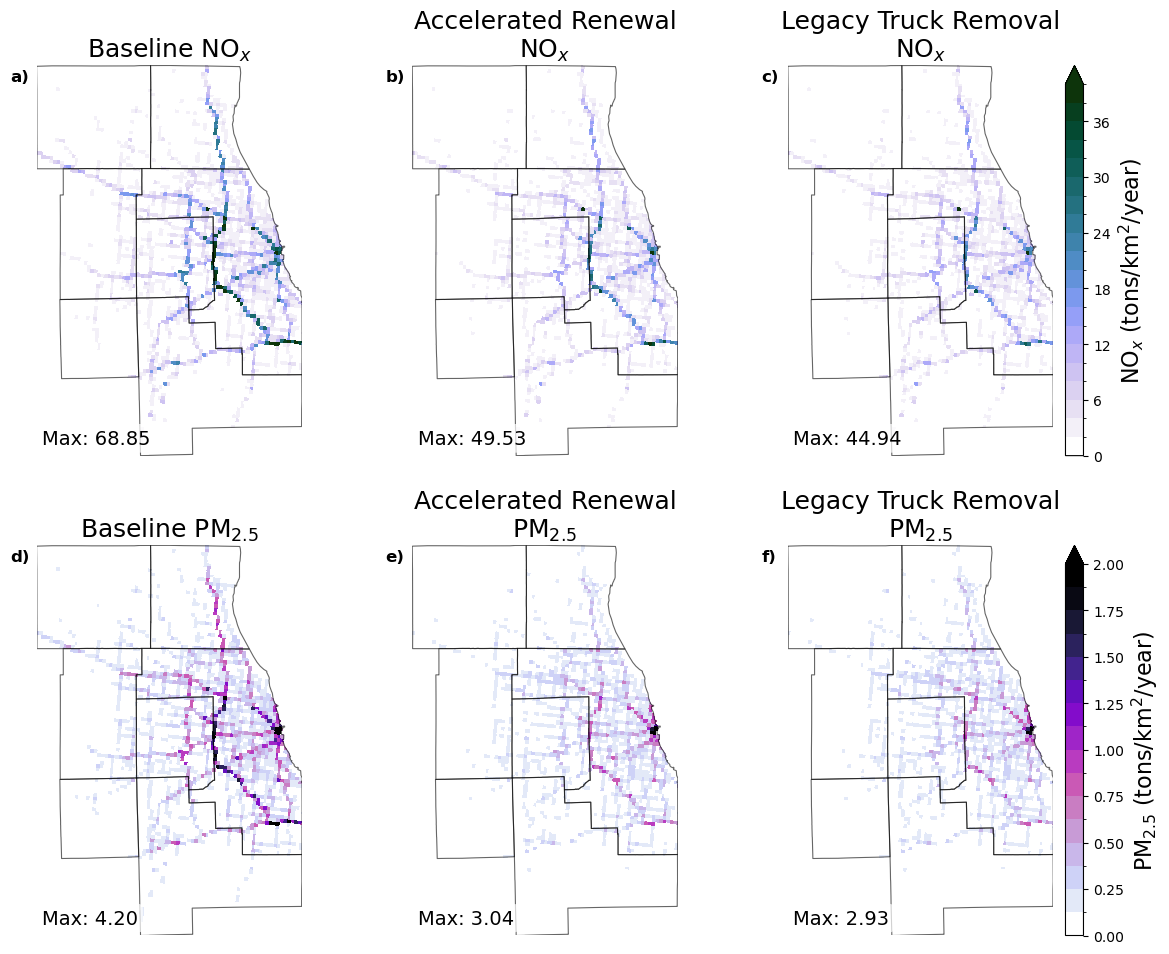

In [24]:
# plot annual NOx and PM2.5 emissions for the baseline, renewal, and removal scenarios
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(12, 10), subplot_kw={"projection": ccrs.PlateCarree()})


# plot NOx across the top row
_panel(axs[0, 0], onroad_total_LOCUSIdlingHDVSpatial_cmap, "NOX_peryear", cmap_abs_nox, norm_abs_nox, NOX_VMIN, NOX_VMAX, "Baseline NO$_x$", ann="max", label="a)")
_panel(axs[0, 1], onroad_total_Renewal_cmap, "NOX_peryear", cmap_abs_nox, norm_abs_nox, NOX_VMIN, NOX_VMAX, "Accelerated Renewal\nNO$_x$", ann="max", label="b)")
_panel(axs[0, 2], onroad_total_ZeroPre2010s_cmap, "NOX_peryear", cmap_abs_nox, norm_abs_nox, NOX_VMIN, NOX_VMAX, "Legacy Truck Removal\nNO$_x$", ann="max", label="c)")


# plot PM2.5 across the bottom row
_panel(axs[1, 0], onroad_total_LOCUSIdlingHDVSpatial_cmap, "PM25_peryear", cmap_abs_pm, norm_abs_pm, PM25_VMIN, PM25_VMAX, "Baseline PM$_{2.5}$", ann="max", label="d)")
_panel(axs[1, 1], onroad_total_Renewal_cmap, "PM25_peryear", cmap_abs_pm, norm_abs_pm, PM25_VMIN, PM25_VMAX, "Accelerated Renewal\nPM$_{2.5}$", ann="max", label="e)")
_panel(axs[1, 2], onroad_total_ZeroPre2010s_cmap, "PM25_peryear", cmap_abs_pm, norm_abs_pm, PM25_VMIN, PM25_VMAX, "Legacy Truck Removal\nPM$_{2.5}$", ann="max", label="f)")


# leave room along the right side for one colorbar per row
fig.subplots_adjust(left=0.01, right=0.94, bottom=0.05, top=0.92, wspace=0.03, hspace=0.23)


# line up each colorbar with its corresponding row
pos_top = axs[0, 2].get_position()
pos_bottom = axs[1, 2].get_position()

cax_nox = fig.add_axes([pos_top.x1 + 0.010, pos_top.y0, 0.015, pos_top.height])
cax_pm = fig.add_axes([pos_bottom.x1 + 0.010, pos_bottom.y0, 0.015, pos_bottom.height])


# add the NOx and PM2.5 colorbars
cb_nox = fig.colorbar(plt.cm.ScalarMappable(norm=norm_abs_nox, cmap=cmap_abs_nox), cax=cax_nox, extend="max")
cb_nox.set_label("NO$_x$ (metric tons/km$^2$/year)", fontsize=16)

cb_pm = fig.colorbar(plt.cm.ScalarMappable(norm=norm_abs_pm, cmap=cmap_abs_pm), cax=cax_pm, extend="max")
cb_pm.set_label("PM$_{2.5}$ (metric tons/km$^2$/year)", fontsize=16)

# save figure
plt.savefig("SI_Fig_Original_Base_Renewal_Removal_EmissionComparisons.pdf", dpi=300, bbox_inches="tight")
plt.savefig("SI_Fig_Original_Base_Renewal_Removal_EmissionComparisons.png", dpi=500, bbox_inches="tight")
plt.show()

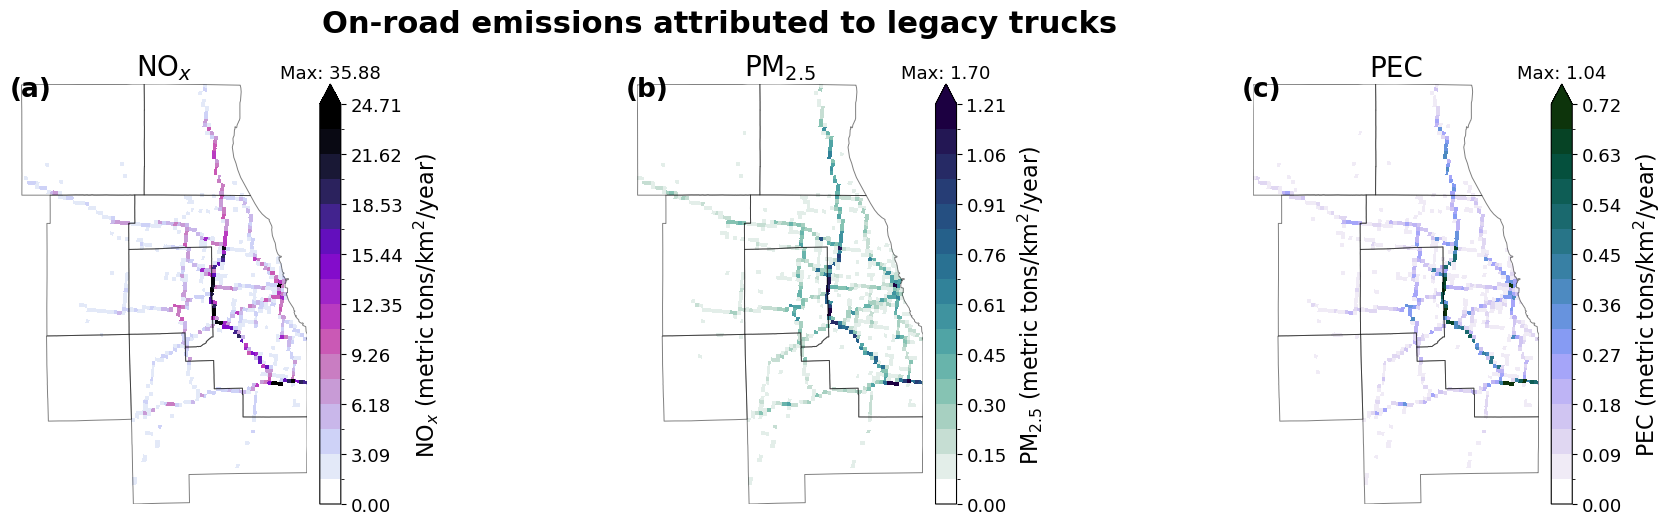

In [31]:
# use baseline minus removal to isolate emissions attributed to legacy trucks
baseline_gdf = onroad_total_LOCUSIdlingHDVSpatial_cmap
removal_gdf = onroad_total_ZeroPre2010s_cmap

seconds_per_year = 3600 * 8760
grams_per_metric_ton = 1e6
cell_area_km2 = 1.33**2
n_bins = 16


# calculate the spatial emissions removed with the legacy trucks
legacy_emissions = baseline_gdf.copy()
legacy_emissions["NOx_removed"] = baseline_gdf["NOX_peryear"] - removal_gdf["NOX_peryear"]
legacy_emissions["PM25_removed"] = baseline_gdf["PM25_peryear"] - removal_gdf["PM25_peryear"]
legacy_emissions["PEC_removed"] = (baseline_gdf["PEC"] - removal_gdf["PEC"]) * seconds_per_year / grams_per_metric_ton / cell_area_km2


# use the same colormaps as the three maps in the other notebook
plot_config = {
    "NOx_removed": {
        "cmap": cmr.gothic_r,
        "title": r"NO$_x$",
        "label": r"NO$_x$ (metric tons/km$^2$/year)"
    },
    "PM25_removed": {
        "cmap": cmr.ocean_r,
        "title": r"PM$_{2.5}$",
        "label": r"PM$_{2.5}$ (metric tons/km$^2$/year)"
    },
    "PEC_removed": {
        "cmap": cmr.horizon_r,
        "title": "PEC",
        "label": r"PEC (metric tons/km$^2$/year)"
    }
}


# give each map roughly a 6 × 5 plotting area
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), subplot_kw={"projection": ccrs.PlateCarree()})


for i, (ax, (col, cfg)) in enumerate(zip(axs, plot_config.items())):
    values_original = legacy_emissions[col].astype(float)
    values_plot = values_original.clip(lower=0)

    # use the 99.9th percentile so isolated extremes do not flatten the spatial pattern
    finite_values = values_plot.to_numpy()
    finite_values = finite_values[np.isfinite(finite_values)]
    vmax = float(np.quantile(finite_values, 0.999)) if finite_values.size else 1e-6
    vmax = vmax if not np.isclose(vmax, 0) else 1e-6

    bounds = np.linspace(0, vmax, n_bins + 1)
    cmap_discrete = ListedColormap(cfg["cmap"](np.linspace(0, 1, n_bins)))
    norm = BoundaryNorm(bounds, cmap_discrete.N)

    # plot the emissions removed with the legacy trucks
    plot_gdf = legacy_emissions.copy()
    plot_gdf[col] = values_plot
    plot_gdf.plot(column=col, ax=ax, cmap=cmap_discrete, norm=norm, edgecolor="none", antialiased=False)

    cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)
    ax.set_extent(extent_xy, crs=ccrs.PlateCarree())
    ax.set_title(cfg["title"], fontsize=20)
    ax.set_axis_off()

    # add the panel label
    ax.text(-0.04, 1.02, f"({chr(97 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=19, fontweight="bold")

    # keep the same discrete colorbar style and show the actual maximum
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_discrete)
    sm.set_array([])

    cbar = fig.colorbar(sm, ax=ax, fraction=0.065, pad=0.025, boundaries=bounds, ticks=bounds[::2], spacing="proportional", extend="max")
    cbar.ax.tick_params(labelsize=13)
    cbar.ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    cbar.set_label(cfg["label"], fontsize=16, labelpad=7)

    actual_values = values_original.to_numpy()
    actual_values = actual_values[np.isfinite(actual_values)]
    actual_max = float(np.max(actual_values)) if actual_values.size else np.nan
    cbar.ax.text(0.5, 1.055, f"Max: {actual_max:.2f}", transform=cbar.ax.transAxes, ha="center", va="bottom", fontsize=13)

fig.suptitle("On-road emissions attributed to legacy trucks", fontsize=22, fontweight="bold", y=1.03)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.04, top=0.88, wspace=0.24)

plt.savefig("SI_Legacy_Truck_Removed_Emissions.pdf", bbox_inches="tight")
plt.savefig("SI_Fig_Legacy_Truck_Removed_Emissions.png", dpi=500, bbox_inches="tight")
plt.show()

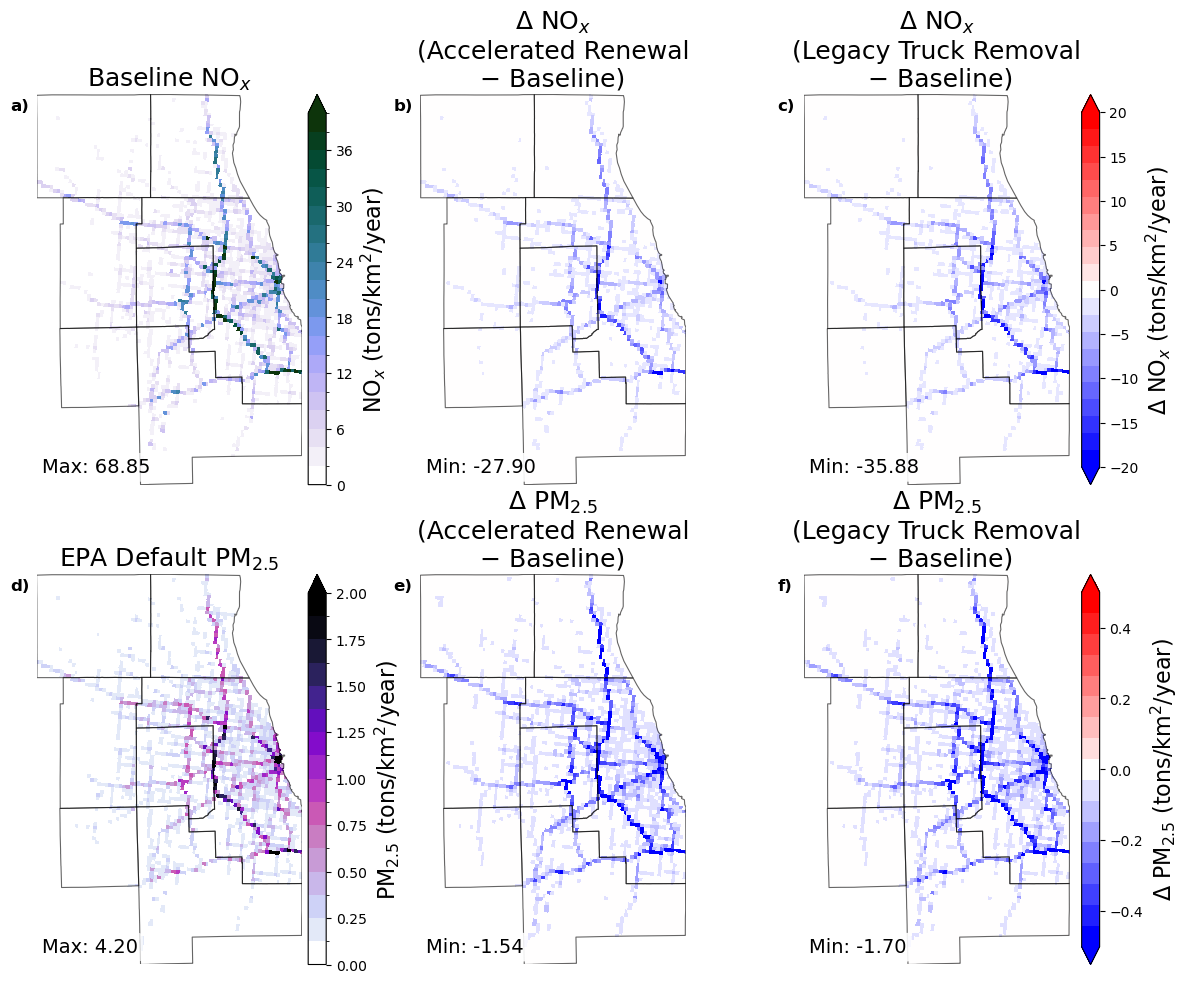

In [27]:
# plot baseline emissions and the changes under accelerated renewal and legacy-truck removal
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(12, 10), subplot_kw={"projection": ccrs.PlateCarree()})

# show the largest reduction in each difference panel
def annotate_minmax(ax, gdf, col, fmt="{:.2f}", color="black"):
    vals = gdf[col].astype(float).to_numpy()
    vals = vals[np.isfinite(vals)]
    vmin = float(np.min(vals)) if vals.size else np.nan
    ax.text(0.02, 0.02, f"Min: {fmt.format(vmin)}", transform=ax.transAxes, ha="left", va="bottom", fontsize=14, color=color, bbox=dict(facecolor="white", alpha=0.90, boxstyle="round,pad=0.25", linewidth=0))

# plot NOx across the top row
_panel(axs[0, 0], onroad_total_LOCUSIdlingHDVSpatial_cmap, "NOX_peryear", cmap_abs_nox, norm_abs_nox, NOX_VMIN, NOX_VMAX, "Baseline NO$_x$", ann="max", label="a)")
_panel(axs[0, 1], onroad_total_Renewal_cmap, "diff_nox", cmap_diff_nox, norm_diff_nox, NOX_DIFF_MIN, NOX_DIFF_MAX, "Δ NO$_x$\n(Accelerated Renewal\n− Baseline)", label="b)")
_panel(axs[0, 2], onroad_total_ZeroPre2010s_cmap, "diff_nox", cmap_diff_nox, norm_diff_nox, NOX_DIFF_MIN, NOX_DIFF_MAX, "Δ NO$_x$\n(Legacy Truck Removal\n− Baseline)", label="c)")

# plot PM2.5 across the bottom row
_panel(axs[1, 0], onroad_total_LOCUSIdlingHDVSpatial_cmap, "PM25_peryear", cmap_abs_pm, norm_abs_pm, PM25_VMIN, PM25_VMAX, "Baseline PM$_{2.5}$", ann="max", label="d)")
_panel(axs[1, 1], onroad_total_Renewal_cmap, "diff_pm25", cmap_diff_pm, norm_diff_pm, PM25_DIFF_MIN, PM25_DIFF_MAX, "Δ PM$_{2.5}$\n(Accelerated Renewal\n− Baseline)", label="e)")
_panel(axs[1, 2], onroad_total_ZeroPre2010s_cmap, "diff_pm25", cmap_diff_pm, norm_diff_pm, PM25_DIFF_MIN, PM25_DIFF_MAX, "Δ PM$_{2.5}$\n(Legacy Truck Removal\n− Baseline)", label="f)")

# leave room for the absolute and difference colorbars
fig.subplots_adjust(left=0.01, right=0.96, bottom=0.05, top=0.92, wspace=0.03, hspace=0.23)

# use the first and last columns to line up the colorbars
pos_col1_top = axs[0, 0].get_position()
pos_col1_bottom = axs[1, 0].get_position()
pos_col3_top = axs[0, 2].get_position()
pos_col3_bottom = axs[1, 2].get_position()

cax_abs_nox = fig.add_axes([pos_col1_top.x1 + 0.005, pos_col1_top.y0, 0.015, pos_col1_top.height])
cax_abs_pm = fig.add_axes([pos_col1_bottom.x1 + 0.005, pos_col1_bottom.y0, 0.015, pos_col1_bottom.height])
cax_diff_nox = fig.add_axes([pos_col3_top.x1 + 0.010, pos_col3_top.y0, 0.015, pos_col3_top.height])
cax_diff_pm = fig.add_axes([pos_col3_bottom.x1 + 0.010, pos_col3_bottom.y0, 0.015, pos_col3_bottom.height])

# add separate colorbars for the absolute emissions and scenario differences
cb_abs_nox = fig.colorbar(plt.cm.ScalarMappable(norm=norm_abs_nox, cmap=cmap_abs_nox), cax=cax_abs_nox, extend="max")
cb_abs_nox.set_label("NO$_x$ (tons/km$^2$/year)", fontsize=16)

cb_diff_nox = fig.colorbar(plt.cm.ScalarMappable(norm=norm_diff_nox, cmap=cmap_diff_nox), cax=cax_diff_nox, extend="both")
cb_diff_nox.set_label("Δ NO$_x$ (tons/km$^2$/year)", fontsize=16)

cb_abs_pm = fig.colorbar(plt.cm.ScalarMappable(norm=norm_abs_pm, cmap=cmap_abs_pm), cax=cax_abs_pm, extend="max")
cb_abs_pm.set_label("PM$_{2.5}$ (tons/km$^2$/year)", fontsize=16)

cb_diff_pm = fig.colorbar(plt.cm.ScalarMappable(norm=norm_diff_pm, cmap=cmap_diff_pm), cax=cax_diff_pm, extend="both")
cb_diff_pm.set_label("Δ PM$_{2.5}$ (tons/km$^2$/year)", fontsize=16)

# save the final figure
plt.savefig("SI_Base_Renewal_Removal_EmissionComparisons.pdf", dpi=300, bbox_inches="tight")
plt.savefig("SI_Base_Renewal_Removal_EmissionComparisons.png", dpi=500, bbox_inches="tight")
plt.show()

<h1> Gas v Diesel Breakdown

In [12]:
def total_tons_per_year_from_density(gdf, density_col, area_crs="EPSG:6933"):
    """Convert emissions in tons/km²/year to total tons/year using the clipped polygon area."""

    if density_col not in gdf.columns:
        raise KeyError(f"Missing column '{density_col}'")

    gdf_area = gdf.to_crs(area_crs)
    area_km2 = gdf_area.geometry.area.to_numpy(dtype=float) / 1e6
    values = gdf[density_col].to_numpy(dtype=float)
    valid = np.isfinite(values) & np.isfinite(area_km2)
    return float(np.sum(values[valid] * area_km2[valid]))

# clip each fuel type to the CMAP counties
gas_base_cmap = gpd.clip(gas_LOCUSIdlingHDVSpatial, cmap_cty)
diesel_base_cmap = gpd.clip(diesel_LOCUSIdlingHDVSpatial, cmap_cty)
gas_renewal_cmap = gpd.clip(gas_Renewal, cmap_cty)
diesel_renewal_cmap = gpd.clip(diesel_Renewal, cmap_cty)
gas_removal_cmap = gpd.clip(gas_ZeroPre2010s, cmap_cty)
diesel_removal_cmap = gpd.clip(diesel_ZeroPre2010s, cmap_cty)

# calculate annual NOx and PM2.5 emission density
gas_base_cmap = calc_pm25_peryear(calc_nox_peryear(gas_base_cmap))
diesel_base_cmap = calc_pm25_peryear(calc_nox_peryear(diesel_base_cmap))
gas_renewal_cmap = calc_pm25_peryear(calc_nox_peryear(gas_renewal_cmap))
diesel_renewal_cmap = calc_pm25_peryear(calc_nox_peryear(diesel_renewal_cmap))
gas_removal_cmap = calc_pm25_peryear(calc_nox_peryear(gas_removal_cmap))
diesel_removal_cmap = calc_pm25_peryear(calc_nox_peryear(diesel_removal_cmap))


# organize the fuel-specific emissions for each scenario
scenario_fuels = {
    "Baseline": {
        "Gas": gas_base_cmap,
        "Diesel": diesel_base_cmap},
    "Accelerated Renewal": {
        "Gas": gas_renewal_cmap,
        "Diesel": diesel_renewal_cmap},
    "Legacy Truck Removal": {
        "Gas": gas_removal_cmap,
        "Diesel": diesel_removal_cmap}}

pollutants = {
    "NOx": "NOX_peryear",
    "PM2.5": "PM25_peryear"}

# calculate and print the total and percent contribution from each fuel type
for scenario, fuels in scenario_fuels.items():
    print(f"\n{scenario} emissions by fuel")

    for pollutant, col in pollutants.items():
        gas_total = total_tons_per_year_from_density(fuels["Gas"], col)
        diesel_total = total_tons_per_year_from_density(fuels["Diesel"], col)
        total = gas_total + diesel_total
        gas_pct = 100 * gas_total / total if total != 0 else np.nan
        diesel_pct = 100 * diesel_total / total if total != 0 else np.nan
        print(f"{pollutant:5s} | Gas: {gas_total:,.2f} tons/year ({gas_pct:.1f}%) | Diesel: {diesel_total:,.2f} tons/year ({diesel_pct:.1f}%) | Total: {total:,.2f} tons/year")


Baseline emissions by fuel
NOx   | Gas: 5,053.94 tons/year (21.3%) | Diesel: 18,711.98 tons/year (78.7%) | Total: 23,765.92 tons/year
PM2.5 | Gas: 557.96 tons/year (45.0%) | Diesel: 682.40 tons/year (55.0%) | Total: 1,240.36 tons/year

Accelerated Renewal emissions by fuel
NOx   | Gas: 4,924.13 tons/year (29.3%) | Diesel: 11,876.87 tons/year (70.7%) | Total: 16,801.00 tons/year
PM2.5 | Gas: 553.82 tons/year (66.4%) | Diesel: 280.71 tons/year (33.6%) | Total: 834.53 tons/year

Legacy Truck Removal emissions by fuel
NOx   | Gas: 4,918.10 tons/year (31.1%) | Diesel: 10,919.12 tons/year (68.9%) | Total: 15,837.23 tons/year
PM2.5 | Gas: 552.01 tons/year (67.9%) | Diesel: 260.43 tons/year (32.1%) | Total: 812.44 tons/year


In [22]:
# use the LOCUS idling scenario as the baseline for the policy comparisons
baseline_gdf = onroad_total_LOCUSIdlingHDVSpatial_cmap
renewal_gdf = onroad_total_Renewal_cmap
zero_gdf = onroad_total_ZeroPre2010s_cmap

scenario_gdfs = {
    "Baseline": baseline_gdf,
    "Renewal": renewal_gdf,
    "Zero Legacy": zero_gdf}

cell_area_km2 = 1.33**2
seconds_per_year = 3600 * 8760
grams_per_metric_ton = 1e6

# convert gridded emission density from metric tons/km²/year to metric tons/year
def spatial_tons_year(gdf, col):
    return (gdf[col].fillna(0) * cell_area_km2).sum()

# convert emissions from g/s to metric tons/year
def gs_to_tons_year(gdf, col):
    return gdf[col].fillna(0).sum() * seconds_per_year / grams_per_metric_ton

# convert emissions from mol/s to metric tons/year
def mols_to_tons_year(gdf, col, molecular_weight):
    return gdf[col].fillna(0).sum() * molecular_weight * seconds_per_year / grams_per_metric_ton

# identify the column and conversion needed for each pollutant
pollutants = {
    r"NO$_x$": {"method": "spatial", "column": "NOX_peryear"},
    r"PM$_{2.5}$": {"method": "spatial", "column": "PM25_peryear"},
    "PEC": {"method": "gs", "column": "PEC"},
    r"NH$_3$": {"method": "mols", "column": "NH3", "molecular_weight": 17.031},
    r"N$_2$O": {"method": "gs", "column": "N2O_INV"},
    r"CO$_2$": {"method": "gs", "column": "CO2_INV"}}

# use the right unit conversion for each pollutant
def calculate_total(gdf, cfg):
    if cfg["method"] == "spatial":
        return spatial_tons_year(gdf, cfg["column"])
    if cfg["method"] == "mols":
        return mols_to_tons_year(gdf, cfg["column"], cfg["molecular_weight"])
    return gs_to_tons_year(gdf, cfg["column"])


rows = []

for pollutant, cfg in pollutants.items():
    col = cfg["column"]

    # make sure every scenario includes the pollutant before calculating the differences
    for scenario, gdf in scenario_gdfs.items():
        if col not in gdf.columns:
            raise KeyError(f"Column '{col}' not found in the {scenario} dataframe.")

    # calculate total annual emissions for each scenario
    totals = {scenario: calculate_total(gdf, cfg) for scenario, gdf in scenario_gdfs.items()}

    baseline = totals["Baseline"]
    renewal = totals["Renewal"]
    zero = totals["Zero Legacy"]

    # separate the full legacy contribution from the portion removed through renewal
    legacy = baseline - zero
    removed = baseline - renewal
    remaining = renewal - zero

    # express each component relative to total baseline or legacy-truck emissions
    legacy_pct_total = legacy / baseline * 100 if baseline != 0 else np.nan
    removed_pct_total = removed / baseline * 100 if baseline != 0 else np.nan
    remaining_pct_total = remaining / baseline * 100 if baseline != 0 else np.nan
    removed_pct_legacy = removed / legacy * 100 if legacy != 0 else np.nan

    rows.append({
        "Pollutant": pollutant,
        "Total": baseline,
        "Legacy": legacy,
        "Removed": removed,
        "Remaining": remaining,
        "Legacy % Total": legacy_pct_total,
        "Removed % Total": removed_pct_total,
        "Remaining % Total": remaining_pct_total,
        "Removed % Legacy": removed_pct_legacy
    })


# use this dataframe for the emissions bar plot
emissions_summary = pd.DataFrame(rows)
display(emissions_summary)

,Pollutant,Total,Legacy,Removed,Remaining,Legacy % Total,Removed % Total,Remaining % Total,Removed % Legacy
0,NO$_x$,2.362153e+04,7.841144e+03,6887.043587,954.100092,33.194898,29.155787,4.039112,87.832131
1,PM$_{2.5}$,1.235790e+03,4.232679e+02,401.350068,21.917823,34.250796,32.477208,1.773588,94.821761
2,PEC,4.614877e+02,2.464911e+02,242.328159,4.162942,53.412282,52.510212,0.902070,98.311119
3,NH$_3$,3.002071e+03,1.041374e+01,-46.836185,57.249926,0.346885,-1.560129,1.907014,-449.753690
4,N$_2$O,1.340260e+03,-1.519368e+01,-136.849735,121.656050,-1.133637,-10.210688,9.077050,900.701445
5,CO$_2$,3.087041e+07,1.456823e+06,508936.090323,947886.578056,4.719156,1.648621,3.070535,34.934663


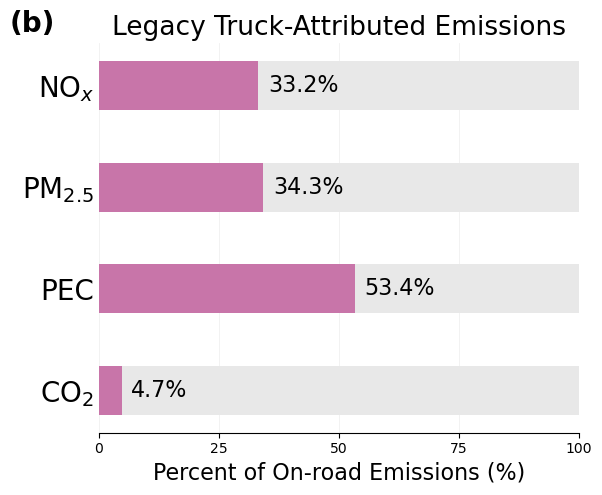

In [30]:
# plot the fraction of total on-road emissions attributed to legacy trucks
plot_order = [r"NO$_x$", r"PM$_{2.5}$", "PEC", r"CO$_2$"]
plot_df = emissions_summary.set_index("Pollutant").loc[plot_order].reset_index()

y = np.arange(len(plot_df))
legacy_color = "#C875A9"
background_color = "#E8E8E8"

fig, ax = plt.subplots(figsize=(6, 5))

# use the gray bars to represent total baseline on-road emissions
ax.barh(y, 100, height=0.48, color=background_color, edgecolor="none")

# overlay the fraction attributed to legacy trucks
ax.barh(y, plot_df["Legacy % Total"], height=0.48, color=legacy_color, edgecolor="none")


# add the percentage next to each bar
for i, pct in enumerate(plot_df["Legacy % Total"]):
    ax.text(pct + 2, i, f"{pct:.1f}%", va="center", ha="left", fontsize=16)


# label and order the pollutants
ax.set_yticks(y)
ax.set_yticklabels(plot_order, fontsize=20)
ax.invert_yaxis()


# format the percent axis
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("Percent of On-road Emissions (%)", fontsize=16)

ax.set_title("Legacy Truck-Attributed Emissions",fontsize=19)
# keep the styling clean
ax.grid(axis="x", linewidth=0.6, alpha=0.18)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", labelsize=10)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_linewidth(0.8)


# add the panel label
fig.text(0.005, 0.98, "(b)", ha="left", va="top", fontsize=20, fontweight="bold")

plt.tight_layout()
plt.show()

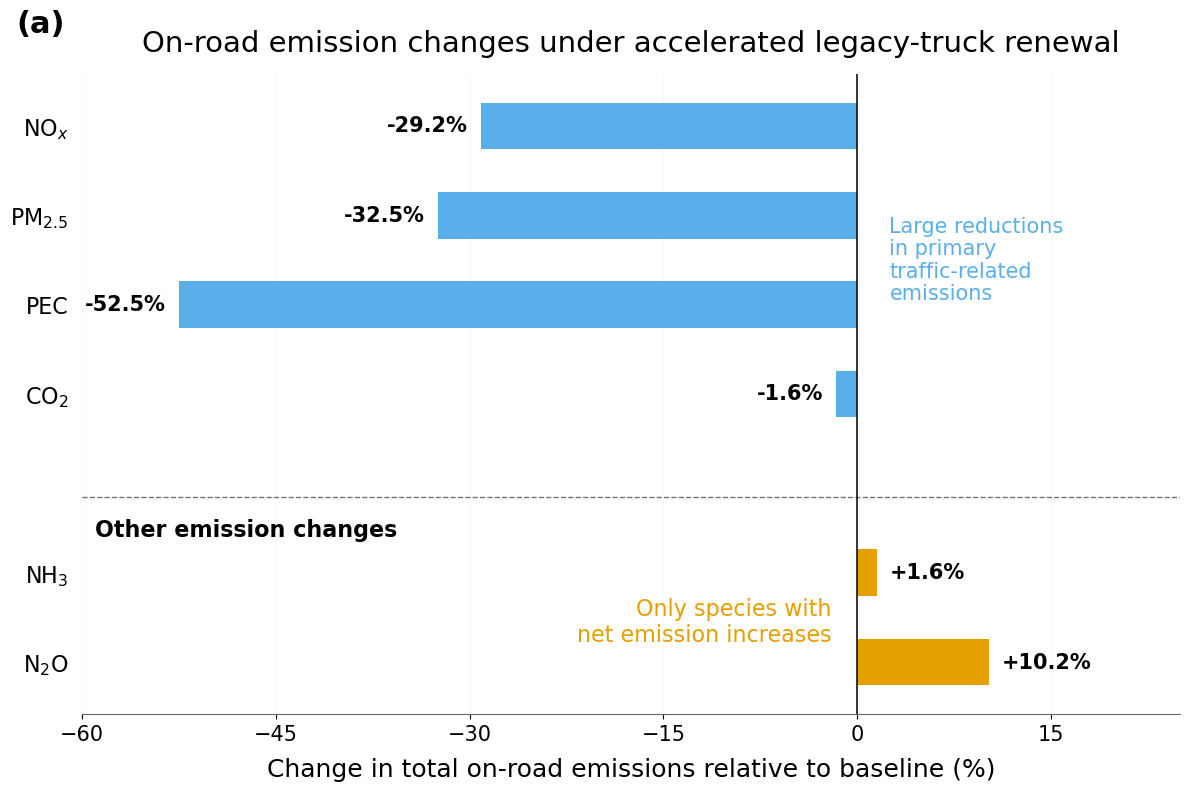

In [23]:
# show how accelerated renewal changes total on-road emissions relative to the LOCUS idling baseline
reduction_order = [r"NO$_x$", r"PM$_{2.5}$", "PEC", r"CO$_2$"]
increase_order = [r"NH$_3$", r"N$_2$O"]

emissions_by_pollutant = emissions_summary.set_index("Pollutant")
reduction_df = emissions_by_pollutant.loc[reduction_order]
increase_df = emissions_by_pollutant.loc[increase_order]

# convert baseline minus renewal into renewal minus baseline so reductions plot as negative
reduction_values = -reduction_df["Removed % Total"].to_numpy()
increase_values = -increase_df["Removed % Total"].to_numpy()

# leave a little extra space between the main pollutants and the emission increases
y_reduction = np.array([0, 1, 2, 3])
y_increase = np.array([5.0, 6.0])

reduction_color = cmr.prinsenvlag(0.80)
increase_color = "#E69F00"

fig, ax = plt.subplots(figsize=(12, 8))


# plot reductions to the left of zero and increases to the right
ax.barh(y_reduction, reduction_values, height=0.52, color=reduction_color, edgecolor="none", zorder=3)
ax.barh(y_increase, increase_values, height=0.52, color=increase_color, edgecolor="none", zorder=3)


# add the percent change next to each bar
for y, value in zip(y_reduction, reduction_values):
    ax.text(value - 1.0, y, f"{value:.1f}%", ha="right", va="center", fontsize=15, fontweight="bold")

for y, value in zip(y_increase, increase_values):
    ax.text(value + 1.0, y, f"{value:+.1f}%", ha="left", va="center", fontsize=15, fontweight="bold")


# separate the primary traffic-related pollutants from the species that increase
ax.axhline(4.15, color="0.45", linestyle="--", linewidth=1.0)
ax.text(-59, 4.52, "Other emission changes", ha="left", va="center", fontsize=16, fontweight="bold")


# briefly explain the two sides of the figure
ax.text(2.5, 1.5, "Large reductions\nin primary\ntraffic-related\nemissions", ha="left", va="center", fontsize=15, color=reduction_color, linespacing=1.15)
ax.text(-2.0, 5.55, "Only species with\nnet emission increases", ha="right", va="center", fontsize=16, color=increase_color, linespacing=1.15)


# use zero to separate emission reductions from increases
ax.axvline(0, color="black", linewidth=1.1, zorder=4)


# label and order the pollutants
all_y = np.concatenate([y_reduction, y_increase])
all_labels = reduction_order + increase_order

ax.set_yticks(all_y)
ax.set_yticklabels(all_labels, fontsize=16)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0, pad=10)


# format the percent-change axis
ax.set_xlim(-60, 25)
ax.set_xticks([-60, -45, -30, -15, 0, 15])
ax.set_xlabel("Change in total on-road emissions relative to baseline (%)", fontsize=18, labelpad=10)
ax.tick_params(axis="x", labelsize=15)


# add the title and keep the styling clean
ax.set_title("On-road emission changes under accelerated legacy-truck renewal", fontsize=21, pad=16)
ax.grid(axis="x", linewidth=0.6, alpha=0.10)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_linewidth(0.8)
ax.spines["bottom"].set_color("0.4")


# add the panel label
ax.text(-0.06, 1.10, "(a)", transform=ax.transAxes, ha="left", va="top", fontsize=22, fontweight="bold")

plt.tight_layout()
plt.show()